In [1]:
# ============================================================
# Celda 1: Importación de librerías y configuración inicial
# ============================================================
# En esta celda se importan las librerías necesarias para entrenar,
# evaluar, comparar y guardar modelos de Machine Learning.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings
from sklearn.base import clone

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

DATASET_TOP = "dataset-phishing-final-top25.csv"
DATASET_BALANCEADO = "dataset-phishing-final-balanced-url10-html10-service5.csv"

TARGET_COL = "status"

COLOR_PRIMARIO = "#3A6EA5"
COLOR_SECUNDARIO = "#5DADE2"
COLOR_TERCIARIO = "#95A5A6"

RANDOM_STATE = 42
TEST_SIZE = 0.2

sns.set_theme(style="whitegrid")

In [2]:
# ============================================================
# Celda 2: Carga de datasets finales
# ============================================================
# En esta celda se cargan los datasets finales generados en el
# notebook 04. Se trabajará con dos enfoques:
#
# 1. Top N global
# 2. Selección balanceada por grupos

df_top = pd.read_csv(DATASET_TOP)
df_balanceado = pd.read_csv(DATASET_BALANCEADO)

print("Dataset Top Global:", df_top.shape)
print("Dataset Balanceado:", df_balanceado.shape)

print("\nPrimeras filas Top Global:")
display(df_top.head())

print("\nPrimeras filas Balanceado:")
display(df_balanceado.head())

Dataset Top Global: (11429, 26)
Dataset Balanceado: (11429, 26)

Primeras filas Top Global:


,google_index,domain_age,nb_hyperlinks,nb_www,phish_hints,safe_anchor,longest_word_path,ratio_digits_url,ratio_intHyperlinks,longest_words_raw,domain_in_title,length_words_raw,nb_dots,domain_registration_length,ratio_extRedirection,nb_hyphens,char_repeat,length_hostname,nb_slash,ratio_extHyperlinks,links_in_tags,avg_word_path,domain_with_copyright,ip,ratio_extMedia,status
0,0,-1.307508,-0.420945,1,-0.388992,-0.948603,-0.197675,-0.594606,-0.194131,-0.198991,1,-0.400668,0.379217,-0.549305,2.687599,-0.478010,0.224865,-0.193917,-0.685076,0.606135,0.674784,-0.082904,0,0,-0.605252,0
1,0,0.548497,-0.342987,0,-0.388992,1.610694,0.928947,1.875996,0.967376,0.751942,0,-0.400668,-1.081050,-0.510030,-0.596479,-0.478010,0.224865,0.177241,0.377519,-0.760630,1.156476,1.339596,1,1,-0.084187,1
2,0,-0.018794,-0.498903,0,-0.388992,1.610694,0.278973,1.092832,1.055922,0.072704,0,1.034997,1.109351,-0.587353,-0.596479,0.001132,-0.194519,2.682560,0.377519,-0.864823,1.156476,0.426797,1,1,-0.605252,1
3,1,-1.307508,0.370626,0,-0.388992,0.650958,-0.457664,-0.594606,0.984610,-0.470686,0,-0.939042,-0.350916,-0.528440,0.341829,-0.478010,-0.613902,-0.936234,-1.216374,-0.780909,1.156476,-0.712535,1,0,-0.512205,0
4,1,1.323334,0.088778,1,-0.388992,-0.948603,0.018983,-0.594606,-0.350388,-0.198991,1,-0.041752,-0.350916,-0.329610,1.419146,0.480274,0.015173,-0.565075,0.377519,0.790005,0.589780,0.266891,0,0,2.000075,0



Primeras filas Balanceado:


,nb_www,phish_hints,longest_word_path,ratio_digits_url,longest_words_raw,length_words_raw,nb_dots,nb_hyphens,char_repeat,length_hostname,nb_hyperlinks,safe_anchor,ratio_intHyperlinks,domain_in_title,ratio_extRedirection,ratio_extHyperlinks,links_in_tags,domain_with_copyright,ratio_extMedia,ratio_extErrors,google_index,domain_age,domain_registration_length,dns_record,whois_registered_domain,status
0,1,-0.388992,-0.197675,-0.594606,-0.198991,-0.400668,0.379217,-0.478010,0.224865,-0.193917,-0.420945,-0.948603,-0.194131,1,2.687599,0.606135,0.674784,0,-0.605252,2.800926,0,-1.307508,-0.549305,0,1,0
1,0,-0.388992,0.928947,1.875996,0.751942,-0.400668,-1.081050,-0.478010,0.224865,0.177241,-0.342987,1.610694,0.967376,0,-0.596479,-0.760630,1.156476,1,-0.084187,-0.399943,0,0.548497,-0.510030,1,1,1
2,0,-0.388992,0.278973,1.092832,0.072704,1.034997,1.109351,0.001132,-0.194519,2.682560,-0.498903,1.610694,1.055922,0,-0.596479,-0.864823,1.156476,1,-0.605252,-0.399943,0,-0.018794,-0.587353,1,1,1
3,0,-0.388992,-0.457664,-0.594606,-0.470686,-0.939042,-0.350916,-0.478010,-0.613902,-0.936234,0.370626,0.650958,0.984610,0,0.341829,-0.780909,1.156476,1,-0.512205,1.200492,1,-1.307508,-0.528440,1,1,0
4,1,-0.388992,0.018983,-0.594606,-0.198991,-0.041752,-0.350916,0.480274,0.015173,-0.565075,0.088778,-0.948603,-0.350388,1,1.419146,0.790005,0.589780,0,2.000075,-0.281392,1,1.323334,-0.329610,1,1,0


In [3]:
# ============================================================
# Celda 3: Separación de variables predictoras y objetivo
# ============================================================
# En esta celda se separan las variables predictoras y la variable
# objetivo para ambos datasets.

X_top = df_top.drop(columns=[TARGET_COL])
y_top = df_top[TARGET_COL]

X_balanceado = df_balanceado.drop(columns=[TARGET_COL])
y_balanceado = df_balanceado[TARGET_COL]

print("X_top:", X_top.shape)
print("y_top:", y_top.shape)

print("\nX_balanceado:", X_balanceado.shape)
print("y_balanceado:", y_balanceado.shape)

print("\nDistribución Top Global:")
display(y_top.value_counts())

print("\nDistribución Balanceado:")
display(y_balanceado.value_counts())

X_top: (11429, 25)
y_top: (11429,)

X_balanceado: (11429, 25)
y_balanceado: (11429,)

Distribución Top Global:


status
0    5715
1    5714
Name: count, dtype: int64


Distribución Balanceado:


status
0    5715
1    5714
Name: count, dtype: int64

In [4]:
# ============================================================
# Celda 4: División train/test
# ============================================================
# En esta celda se divide cada dataset en entrenamiento y prueba.
# Se utiliza stratify para conservar la proporción de clases.

X_top_train, X_top_test, y_top_train, y_top_test = train_test_split(
    X_top,
    y_top,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_top
)

X_bal_train, X_bal_test, y_bal_train, y_bal_test = train_test_split(
    X_balanceado,
    y_balanceado,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_balanceado
)

print("Top Global:")
print("Train:", X_top_train.shape)
print("Test:", X_top_test.shape)

print("\nBalanceado:")
print("Train:", X_bal_train.shape)
print("Test:", X_bal_test.shape)

Top Global:
Train: (9143, 25)
Test: (2286, 25)

Balanceado:
Train: (9143, 25)
Test: (2286, 25)


In [5]:
# ============================================================
# Celda 5: Función general de entrenamiento y evaluación
# ============================================================
# En esta celda se define una función reutilizable para entrenar
# modelos de Machine Learning, calcular métricas y generar gráficos
# de evaluación como matriz de confusión.

resultados_modelos = []

modelos_entrenados = {}

def entrenar_evaluar_modelo(
    modelo,
    nombre_modelo,
    nombre_dataset,
    X_train,
    X_test,
    y_train,
    y_test
):
    # =========================
    # Entrenamiento
    # =========================
    
    modelo.fit(X_train, y_train)

    # =========================
    # Predicciones
    # =========================

    y_pred = modelo.predict(X_test)

    if hasattr(modelo, "predict_proba"):
        y_proba = modelo.predict_proba(X_test)[:, 1]
    else:
        y_proba = None

    # =========================
    # Métricas
    # =========================

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    if y_proba is not None:
        roc_auc = roc_auc_score(y_test, y_proba)
    else:
        roc_auc = np.nan

    resultados_modelos.append({
        "dataset": nombre_dataset,
        "modelo": nombre_modelo,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "roc_auc": roc_auc
    })

    modelos_entrenados[f"{nombre_dataset}_{nombre_modelo}"] = modelo

    # =========================
    # Resultados en texto
    # =========================

    print("=" * 70)
    print(f"Modelo: {nombre_modelo}")
    print(f"Dataset: {nombre_dataset}")
    print("=" * 70)

    print("\nMétricas:")
    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1-score :", round(f1, 4))
    print("ROC-AUC  :", round(roc_auc, 4) if not np.isnan(roc_auc) else "No disponible")

    print("\nReporte de clasificación:")
    print(classification_report(y_test, y_pred))

    # =========================
    # Gráfico: matriz de confusión
    # =========================

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legítima", "Phishing"],
        yticklabels=["Legítima", "Phishing"]
    )

    plt.title(
        f"Matriz de confusión\n{nombre_modelo} - {nombre_dataset}",
        fontsize=13,
        fontweight="bold"
    )

    plt.xlabel("Predicción")
    plt.ylabel("Valor real")

    plt.tight_layout()
    plt.show()

    return modelo

In [6]:
# ============================================================
# Celda 6: Definición de modelos de Machine Learning
# ============================================================
# En esta celda se definen los modelos que serán entrenados y evaluados
# sobre ambos datasets: Top Global y Balanceado.

modelos_ml = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        class_weight="balanced"
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE,
        class_weight="balanced"
    )
}

print("Modelos definidos:")
for nombre in modelos_ml.keys():
    print("-", nombre)

Modelos definidos:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- KNN
- SVM




################################################################################
ENTRENANDO MODELO: Logistic Regression
################################################################################
Modelo: Logistic Regression
Dataset: Top Global

Métricas:
Accuracy : 0.9143
Precision: 0.9064
Recall   : 0.9239
F1-score : 0.9151
ROC-AUC  : 0.9682

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.92      0.90      0.91      1143
           1       0.91      0.92      0.92      1143

    accuracy                           0.91      2286
   macro avg       0.91      0.91      0.91      2286
weighted avg       0.91      0.91      0.91      2286



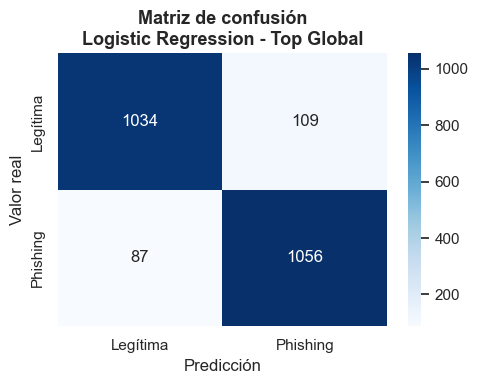

Modelo: Logistic Regression
Dataset: Balanceado

Métricas:
Accuracy : 0.9121
Precision: 0.9033
Recall   : 0.923
F1-score : 0.913
ROC-AUC  : 0.9682

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.92      0.90      0.91      1143
           1       0.90      0.92      0.91      1143

    accuracy                           0.91      2286
   macro avg       0.91      0.91      0.91      2286
weighted avg       0.91      0.91      0.91      2286



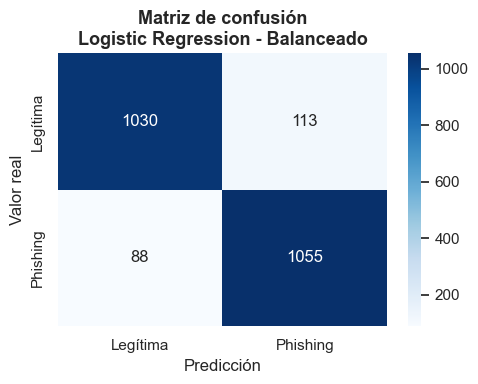



################################################################################
ENTRENANDO MODELO: Decision Tree
################################################################################
Modelo: Decision Tree
Dataset: Top Global

Métricas:
Accuracy : 0.9173
Precision: 0.9141
Recall   : 0.9213
F1-score : 0.9176
ROC-AUC  : 0.9173

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.92      0.91      0.92      1143
           1       0.91      0.92      0.92      1143

    accuracy                           0.92      2286
   macro avg       0.92      0.92      0.92      2286
weighted avg       0.92      0.92      0.92      2286



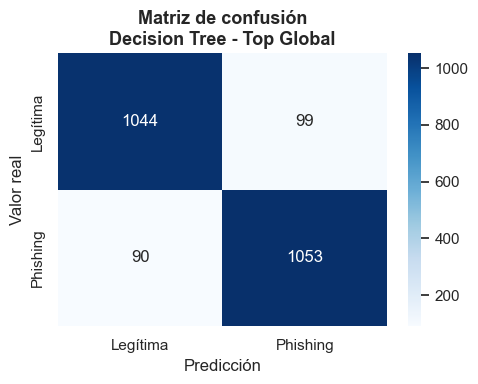

Modelo: Decision Tree
Dataset: Balanceado

Métricas:
Accuracy : 0.9195
Precision: 0.9277
Recall   : 0.9099
F1-score : 0.9187
ROC-AUC  : 0.9195

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.91      0.93      0.92      1143
           1       0.93      0.91      0.92      1143

    accuracy                           0.92      2286
   macro avg       0.92      0.92      0.92      2286
weighted avg       0.92      0.92      0.92      2286



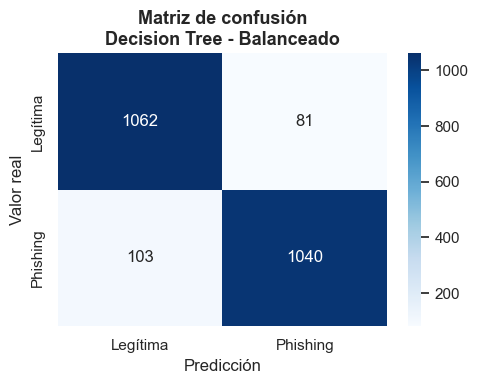



################################################################################
ENTRENANDO MODELO: Random Forest
################################################################################
Modelo: Random Forest
Dataset: Top Global

Métricas:
Accuracy : 0.9488
Precision: 0.9445
Recall   : 0.9536
F1-score : 0.9491
ROC-AUC  : 0.9864

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.95      0.94      0.95      1143
           1       0.94      0.95      0.95      1143

    accuracy                           0.95      2286
   macro avg       0.95      0.95      0.95      2286
weighted avg       0.95      0.95      0.95      2286



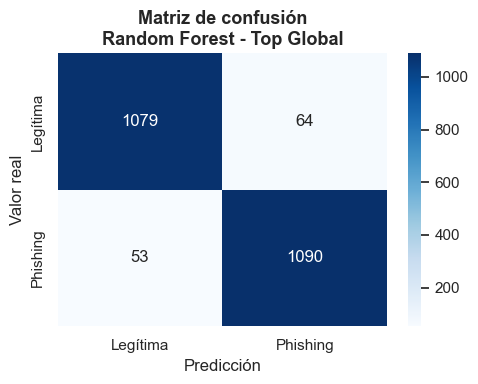

Modelo: Random Forest
Dataset: Balanceado

Métricas:
Accuracy : 0.9462
Precision: 0.9427
Recall   : 0.9501
F1-score : 0.9464
ROC-AUC  : 0.9859

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.95      0.94      0.95      1143
           1       0.94      0.95      0.95      1143

    accuracy                           0.95      2286
   macro avg       0.95      0.95      0.95      2286
weighted avg       0.95      0.95      0.95      2286



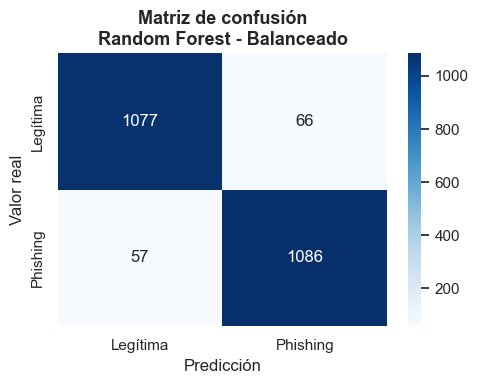



################################################################################
ENTRENANDO MODELO: Gradient Boosting
################################################################################
Modelo: Gradient Boosting
Dataset: Top Global

Métricas:
Accuracy : 0.9392
Precision: 0.9328
Recall   : 0.9466
F1-score : 0.9396
ROC-AUC  : 0.983

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.95      0.93      0.94      1143
           1       0.93      0.95      0.94      1143

    accuracy                           0.94      2286
   macro avg       0.94      0.94      0.94      2286
weighted avg       0.94      0.94      0.94      2286



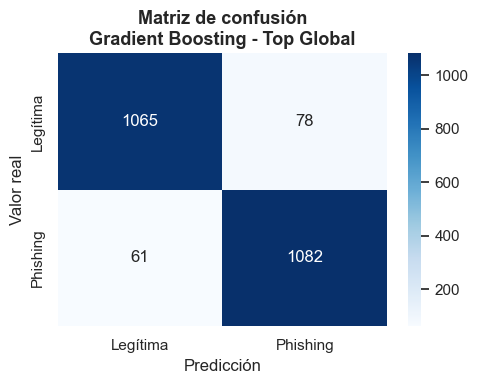

Modelo: Gradient Boosting
Dataset: Balanceado

Métricas:
Accuracy : 0.937
Precision: 0.9302
Recall   : 0.9449
F1-score : 0.9375
ROC-AUC  : 0.9821

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.94      0.93      0.94      1143
           1       0.93      0.94      0.94      1143

    accuracy                           0.94      2286
   macro avg       0.94      0.94      0.94      2286
weighted avg       0.94      0.94      0.94      2286



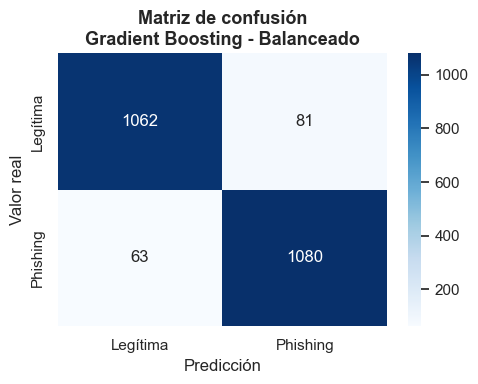



################################################################################
ENTRENANDO MODELO: KNN
################################################################################
Modelo: KNN
Dataset: Top Global

Métricas:
Accuracy : 0.9361
Precision: 0.9346
Recall   : 0.9379
F1-score : 0.9362
ROC-AUC  : 0.9638

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.94      0.93      0.94      1143
           1       0.93      0.94      0.94      1143

    accuracy                           0.94      2286
   macro avg       0.94      0.94      0.94      2286
weighted avg       0.94      0.94      0.94      2286



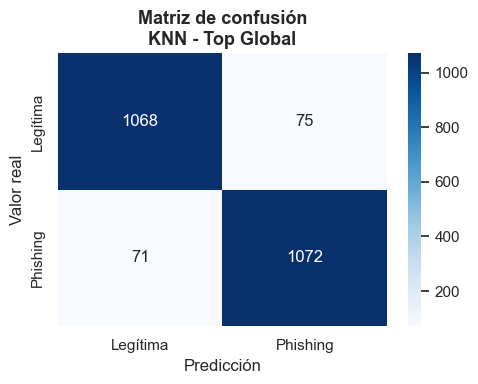

Modelo: KNN
Dataset: Balanceado

Métricas:
Accuracy : 0.9296
Precision: 0.9277
Recall   : 0.9318
F1-score : 0.9297
ROC-AUC  : 0.9659

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93      1143
           1       0.93      0.93      0.93      1143

    accuracy                           0.93      2286
   macro avg       0.93      0.93      0.93      2286
weighted avg       0.93      0.93      0.93      2286



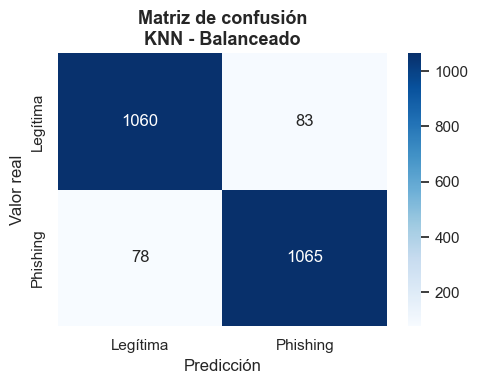



################################################################################
ENTRENANDO MODELO: SVM
################################################################################
Modelo: SVM
Dataset: Top Global

Métricas:
Accuracy : 0.9374
Precision: 0.9333
Recall   : 0.9423
F1-score : 0.9377
ROC-AUC  : 0.9797

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.94      0.93      0.94      1143
           1       0.93      0.94      0.94      1143

    accuracy                           0.94      2286
   macro avg       0.94      0.94      0.94      2286
weighted avg       0.94      0.94      0.94      2286



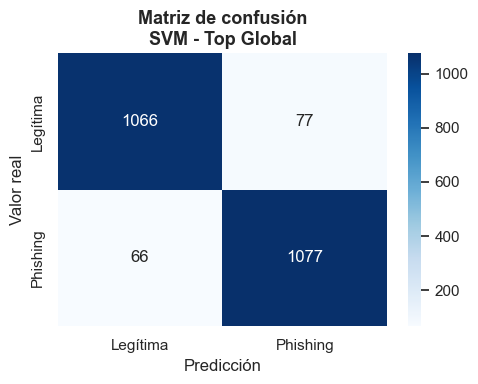

Modelo: SVM
Dataset: Balanceado

Métricas:
Accuracy : 0.9348
Precision: 0.9284
Recall   : 0.9423
F1-score : 0.9353
ROC-AUC  : 0.9796

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.94      0.93      0.93      1143
           1       0.93      0.94      0.94      1143

    accuracy                           0.93      2286
   macro avg       0.93      0.93      0.93      2286
weighted avg       0.93      0.93      0.93      2286



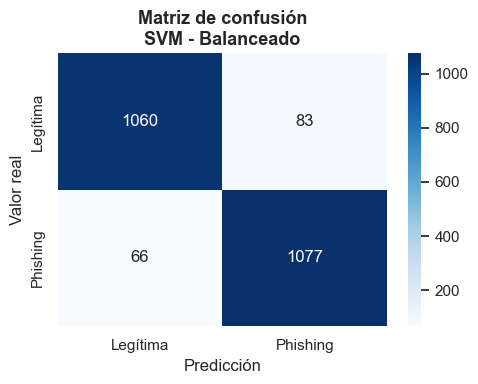

In [7]:
# ============================================================
# Celda 7: Entrenamiento y evaluación de modelos
# ============================================================
# En esta celda se entrenan todos los modelos definidos previamente
# utilizando ambos datasets:
#
# 1. Dataset Top Global
# 2. Dataset Balanceado
#
# Cada modelo genera sus métricas y matriz de confusión.

for nombre_modelo, modelo in modelos_ml.items():

    print("\n\n" + "#" * 80)
    print(f"ENTRENANDO MODELO: {nombre_modelo}")
    print("#" * 80)

    entrenar_evaluar_modelo(
        modelo=clone(modelo),
        nombre_modelo=nombre_modelo,
        nombre_dataset="Top Global",
        X_train=X_top_train,
        X_test=X_top_test,
        y_train=y_top_train,
        y_test=y_top_test
    )

    entrenar_evaluar_modelo(
        modelo=clone(modelo),
        nombre_modelo=nombre_modelo,
        nombre_dataset="Balanceado",
        X_train=X_bal_train,
        X_test=X_bal_test,
        y_train=y_bal_train,
        y_test=y_bal_test
    )

Resumen general de modelos:


,dataset,modelo,accuracy,precision,recall,f1_score,roc_auc
4,Top Global,Random Forest,0.948819,0.944541,0.953631,0.949064,0.986419
5,Balanceado,Random Forest,0.946194,0.942708,0.950131,0.946405,0.985911
6,Top Global,Gradient Boosting,0.939195,0.932759,0.946632,0.939644,0.983046
10,Top Global,SVM,0.937445,0.933276,0.942257,0.937745,0.979712
7,Balanceado,Gradient Boosting,0.937008,0.930233,0.944882,0.937500,0.982139
8,Top Global,KNN,0.936133,0.934612,0.937883,0.936245,0.963764
11,Balanceado,SVM,0.934821,0.928448,0.942257,0.935302,0.979561
9,Balanceado,KNN,0.929571,0.927700,0.931759,0.929725,0.965893
3,Balanceado,Decision Tree,0.919510,0.927743,0.909886,0.918728,0.919510
2,Top Global,Decision Tree,0.917323,0.914062,0.921260,0.917647,0.917323


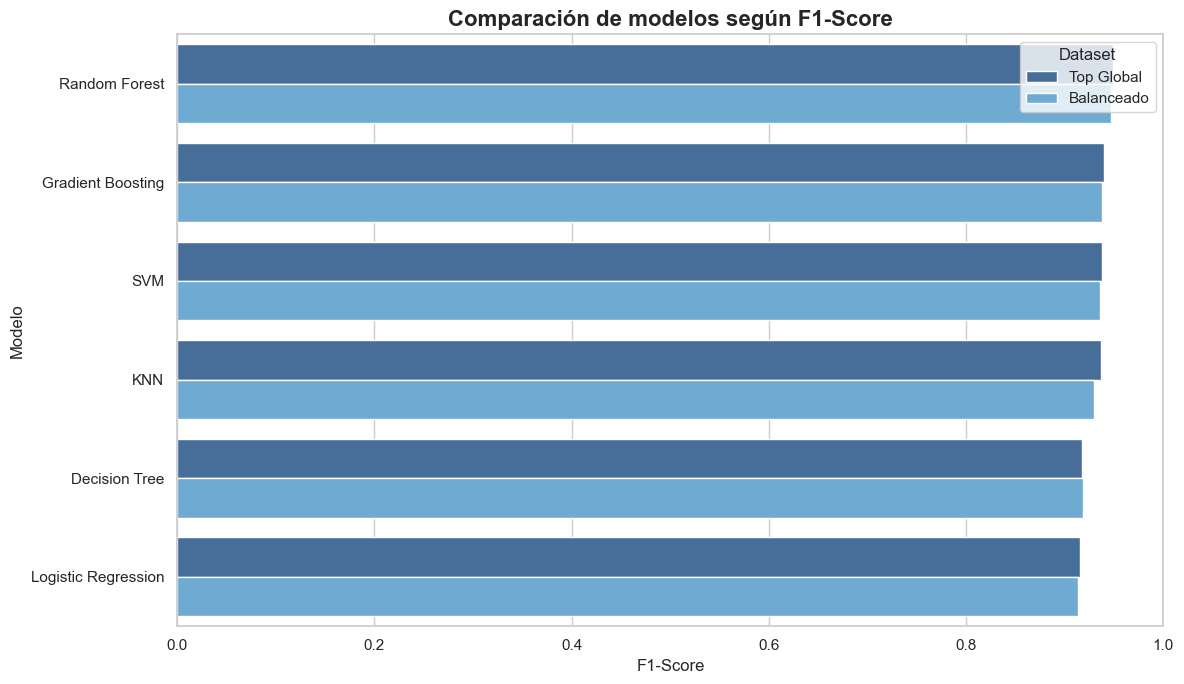

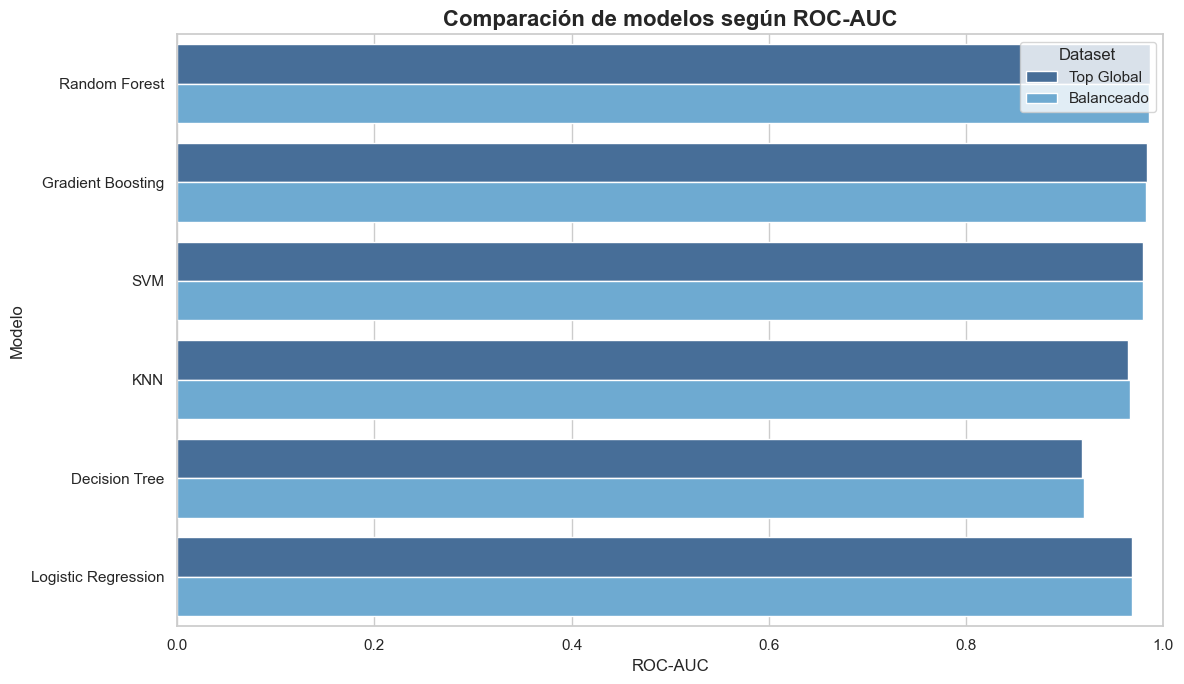

In [8]:
# ============================================================
# Celda 8: Comparación general de resultados
# ============================================================
# En esta celda se consolidan todas las métricas obtenidas
# para comparar el rendimiento de los modelos entrenados.

resultados_df = pd.DataFrame(resultados_modelos)

resultados_df = resultados_df.sort_values(
    by="f1_score",
    ascending=False
)

print("Resumen general de modelos:")
display(resultados_df)

# ============================================================
# Gráfico comparativo F1-Score
# ============================================================

plt.figure(figsize=(12, 7))

sns.barplot(
    data=resultados_df,
    x="f1_score",
    y="modelo",
    hue="dataset",
    palette=[COLOR_PRIMARIO, COLOR_SECUNDARIO]
)

plt.title(
    "Comparación de modelos según F1-Score",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("F1-Score")
plt.ylabel("Modelo")

plt.xlim(0, 1)

plt.legend(title="Dataset")

plt.tight_layout()
plt.show()

# ============================================================
# Gráfico comparativo ROC-AUC
# ============================================================

plt.figure(figsize=(12, 7))

sns.barplot(
    data=resultados_df,
    x="roc_auc",
    y="modelo",
    hue="dataset",
    palette=[COLOR_PRIMARIO, COLOR_SECUNDARIO]
)

plt.title(
    "Comparación de modelos según ROC-AUC",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("ROC-AUC")
plt.ylabel("Modelo")

plt.xlim(0, 1)

plt.legend(title="Dataset")

plt.tight_layout()
plt.show()

In [9]:
# ============================================================
# Celda 9: Identificación del mejor modelo
# ============================================================
# En esta celda se identifica automáticamente el modelo con mejor
# desempeño según el F1-score.
#
# El F1-score es especialmente importante en detección de phishing
# porque balancea precisión y recall.

mejor_resultado = resultados_df.iloc[0]

print("=" * 70)
print("MEJOR MODELO ENCONTRADO")
print("=" * 70)

print(f"Modelo : {mejor_resultado['modelo']}")
print(f"Dataset: {mejor_resultado['dataset']}")

print("\nMétricas:")

print("Accuracy :", round(mejor_resultado["accuracy"], 4))
print("Precision:", round(mejor_resultado["precision"], 4))
print("Recall   :", round(mejor_resultado["recall"], 4))
print("F1-score :", round(mejor_resultado["f1_score"], 4))
print("ROC-AUC  :", round(mejor_resultado["roc_auc"], 4))

# ============================================================
# Obtener modelo ganador
# ============================================================

clave_modelo = (
    f"{mejor_resultado['dataset']}_"
    f"{mejor_resultado['modelo']}"
)

mejor_modelo = modelos_entrenados[clave_modelo]

print("\nClave del modelo ganador:")
print(clave_modelo)

MEJOR MODELO ENCONTRADO
Modelo : Random Forest
Dataset: Top Global

Métricas:
Accuracy : 0.9488
Precision: 0.9445
Recall   : 0.9536
F1-score : 0.9491
ROC-AUC  : 0.9864

Clave del modelo ganador:
Top Global_Random Forest


In [10]:
# ============================================================
# Celda 10: Guardado del mejor modelo de Machine Learning
# ============================================================
# En esta celda se guarda el mejor modelo encontrado junto con
# sus métricas y las columnas utilizadas. Esto permitirá reutilizar
# el modelo posteriormente en una API o sistema de predicción.

os.makedirs("models/ml", exist_ok=True)

# =========================
# Guardar mejor modelo
# =========================

joblib.dump(
    mejor_modelo,
    "models/ml/mejor_modelo_ml.pkl"
)

# =========================
# Guardar métricas
# =========================

mejor_resultado_df = pd.DataFrame([mejor_resultado])

mejor_resultado_df.to_csv(
    "models/ml/metricas_mejor_modelo_ml.csv",
    index=False
)

# =========================
# Guardar features usadas
# =========================

if mejor_resultado["dataset"] == "Top Global":
    features_usadas = X_top.columns.tolist()
else:
    features_usadas = X_balanceado.columns.tolist()

joblib.dump(
    features_usadas,
    "models/ml/features_mejor_modelo_ml.pkl"
)

print("Mejor modelo ML guardado correctamente.")
print("Archivo modelo: models/ml/mejor_modelo_ml.pkl")
print("Archivo métricas: models/ml/metricas_mejor_modelo_ml.csv")
print("Archivo features: models/ml/features_mejor_modelo_ml.pkl")

Mejor modelo ML guardado correctamente.
Archivo modelo: models/ml/mejor_modelo_ml.pkl
Archivo métricas: models/ml/metricas_mejor_modelo_ml.csv
Archivo features: models/ml/features_mejor_modelo_ml.pkl


In [11]:
model = joblib.load("models/ml/mejor_modelo_ml.pkl")
features = joblib.load("models/ml/features_mejor_modelo_ml.pkl")

print(list(model.feature_names_in_) == features)
print(list(model.feature_names_in_))
print(features)

True
['google_index', 'domain_age', 'nb_hyperlinks', 'nb_www', 'phish_hints', 'safe_anchor', 'longest_word_path', 'ratio_digits_url', 'ratio_intHyperlinks', 'longest_words_raw', 'domain_in_title', 'length_words_raw', 'nb_dots', 'domain_registration_length', 'ratio_extRedirection', 'nb_hyphens', 'char_repeat', 'length_hostname', 'nb_slash', 'ratio_extHyperlinks', 'links_in_tags', 'avg_word_path', 'domain_with_copyright', 'ip', 'ratio_extMedia']
['google_index', 'domain_age', 'nb_hyperlinks', 'nb_www', 'phish_hints', 'safe_anchor', 'longest_word_path', 'ratio_digits_url', 'ratio_intHyperlinks', 'longest_words_raw', 'domain_in_title', 'length_words_raw', 'nb_dots', 'domain_registration_length', 'ratio_extRedirection', 'nb_hyphens', 'char_repeat', 'length_hostname', 'nb_slash', 'ratio_extHyperlinks', 'links_in_tags', 'avg_word_path', 'domain_with_copyright', 'ip', 'ratio_extMedia']
